# MODUL 9 - MORFOLOGI CITRA

**Pengolahan Citra dan Visi Komputer**
**Jurusan Teknologi Informasi - Politeknik Negeri Malang**

---

### Identitas:
**Radit Firansah** (NIM: `244107020196`)

---

### Praktikum D - Morfologi


In [1]:
# 1. Mount Google Drive (hanya jika dijalankan di Google Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    print('Bukan lingkungan Google Colab - memakai folder data lokal.')


Bukan lingkungan Google Colab - memakai folder data lokal.


In [2]:
# 2. Import library
%matplotlib inline
import os
import glob
import cv2
import numpy as np
from matplotlib import pyplot as plt
from skimage.morphology import skeletonize, thin

print('OpenCV  :', cv2.__version__)
print('NumPy   :', np.__version__)


OpenCV  : 5.0.0
NumPy   : 2.3.5


In [3]:
# 3. Deteksi folder data + muat semua citra sebagai biner (Otsu)
def cari_folder_data():
    kandidat = ['data', os.path.join('..', 'data'),
                '/content/drive/MyDrive/Minggu-9/data']
    for k in kandidat:
        if os.path.isdir(k) and glob.glob(os.path.join(k, '*.jpg')):
            return k
    if os.path.isdir('/content/drive/MyDrive'):
        for root, _, _ in os.walk('/content/drive/MyDrive'):
            if os.path.basename(root) == 'data' and glob.glob(os.path.join(root, '*.jpg')):
                return root
    raise FileNotFoundError('Folder data tidak ditemukan')


DATA_DIR = cari_folder_data()
FILES = sorted(f for f in glob.glob(os.path.join(DATA_DIR, '*'))
               if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')))
print('Folder :', DATA_DIR)
print('Jumlah :', len(FILES), 'citra')

MAKS_SISI = 300


def muat_biner(path, maks=MAKS_SISI):
    """Baca citra -> grayscale (dibatasi maks px) -> biner Otsu (0/255)."""
    gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    h, w = gray.shape
    if max(h, w) > maks:
        s = maks / max(h, w)
        gray = cv2.resize(gray, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
    _, biner = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return gray, biner


GRAY, BINER = {}, {}
for p in FILES:
    nama = os.path.splitext(os.path.basename(p))[0]
    GRAY[nama], BINER[nama] = muat_biner(p)
    print(f'{nama:12s} ukuran={BINER[nama].shape} foreground={(BINER[nama] > 0).mean():.1%}')


Folder : data
Jumlah : 4 citra
kitten01     ukuran=(280, 300) foreground=20.7%
lily         ukuran=(288, 300) foreground=59.1%
noisy_text   ukuran=(100, 300) foreground=14.8%
plate        ukuran=(66, 225) foreground=13.2%


In [4]:
# 4. Helper tampilan grid: baris = citra, kolom = tahap
def tampil_step(judul_kolom, hasil, judul_utama):
    n, m = len(hasil), len(judul_kolom)
    plt.figure(figsize=(3.2 * m, 2.5 * n))
    for r, (nama, daftar) in enumerate(hasil.items()):
        for c, img in enumerate(daftar):
            ax = plt.subplot(n, m, r * m + c + 1)
            ax.imshow(img, cmap='gray', vmin=0, vmax=255)
            ax.set_title(f'{nama}\n{judul_kolom[c]}', fontsize=8)
            ax.axis('off')
    plt.suptitle(judul_utama, fontsize=13)
    plt.tight_layout()
    plt.show()


## Konversi seluruh citra ke biner

Semua operasi morfologi di bawah memakai citra biner hasil Otsu (objek = putih / 255).

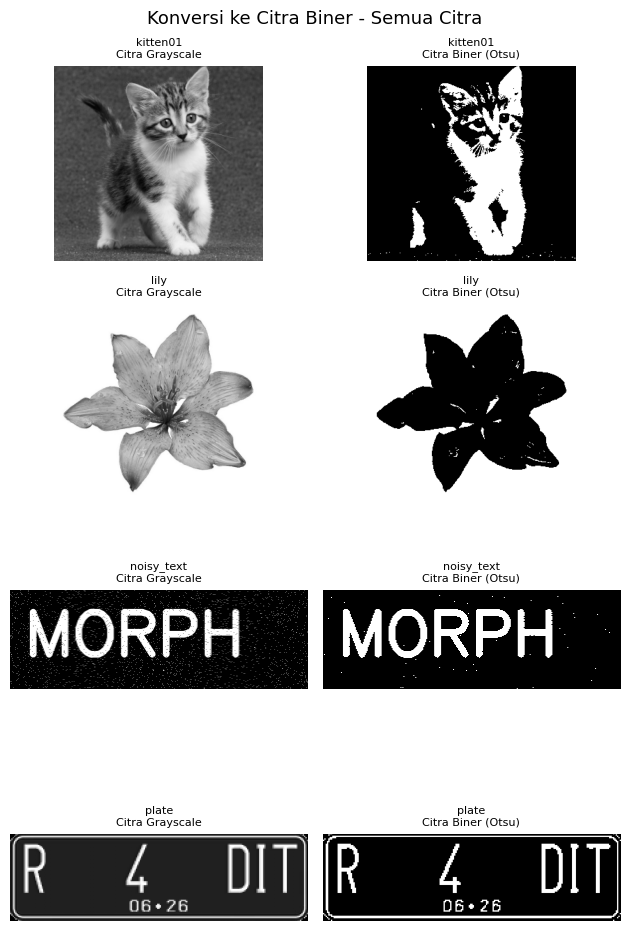

In [5]:
# 5. Tampilkan grayscale vs biner untuk semua citra
hasil = {n: [GRAY[n], BINER[n]] for n in GRAY}
tampil_step(['Citra Grayscale', 'Citra Biner (Otsu)'], hasil,
            'Konversi ke Citra Biner - Semua Citra')


## Fungsi morfologi manual (tanpa library `morphology` OpenCV)

Sama seperti modul, dilasi = `max` dan erosi = `min` dari ketetanggaan yang dikalikan
structuring element. Ukuran `SE` mengikuti bentuk yang diminta (`cross`, `square`,
`circle`, `rectangle`, `line`).

In [6]:
# 6. Fungsi dilasi & erosi manual + pembuat structuring element
def dilasi_manual(F, SE):
    p, q = F.shape
    rh, rw = SE.shape[0] // 2, SE.shape[1] // 2
    # border replicate agar piksel tepi diperlakukan sama seperti cv2.dilate
    P = cv2.copyMakeBorder(F, rh, rh, rw, rw, cv2.BORDER_REPLICATE)
    out = np.zeros((p, q), dtype=np.uint8)
    for i in range(p):
        for j in range(q):
            out[i, j] = np.max(P[i:i + SE.shape[0], j:j + SE.shape[1]] * SE)
    return out


def erosi_manual(F, SE):
    p, q = F.shape
    rh, rw = SE.shape[0] // 2, SE.shape[1] // 2
    P = cv2.copyMakeBorder(F, rh, rh, rw, rw, cv2.BORDER_REPLICATE)
    out = np.zeros((p, q), dtype=np.uint8)
    for i in range(p):
        for j in range(q):
            out[i, j] = np.min(P[i:i + SE.shape[0], j:j + SE.shape[1]] * SE)
    return out


def se_square(w):
    return np.ones((w, w), dtype=np.uint8)


def se_cross(w):
    return cv2.getStructuringElement(cv2.MORPH_CROSS, (w, w))


def se_circle(w):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))


def se_rect(tinggi, lebar):
    return cv2.getStructuringElement(cv2.MORPH_RECT, (lebar, tinggi))


def se_line_vertikal(k):
    return np.ones((k, 1), dtype=np.uint8)


print('Fungsi siap.')


Fungsi siap.


### 3. Dilasi manual - SE square 5x5

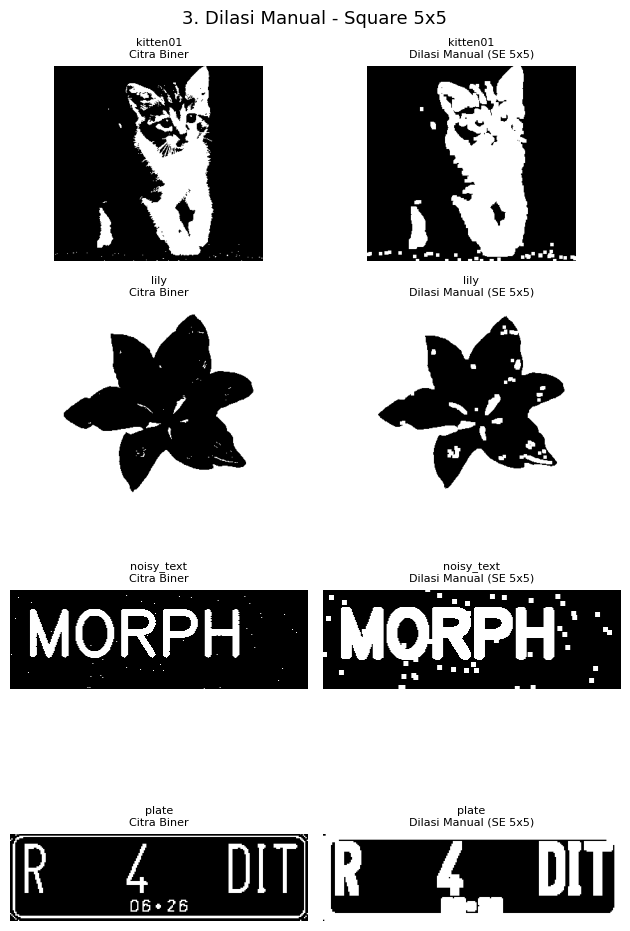

In [7]:
# 7. Dilasi manual SE square 5x5
SE = se_square(5)
hasil = {n: [BINER[n], dilasi_manual(BINER[n], SE)] for n in BINER}
tampil_step(['Citra Biner', 'Dilasi Manual (SE 5x5)'], hasil,
            '3. Dilasi Manual - Square 5x5')


### 4. Dilasi dengan library OpenCV - SE cross 3x3

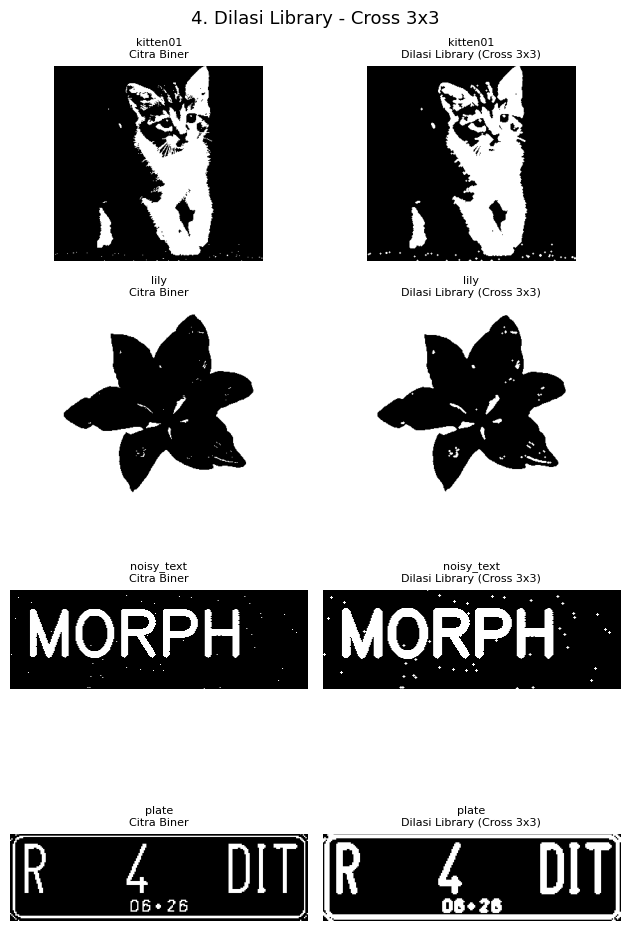

In [8]:
# 8. Dilasi library cv2.dilate SE cross 3x3
SE = se_cross(3)
hasil = {n: [BINER[n], cv2.dilate(BINER[n], SE, iterations=1)] for n in BINER}
tampil_step(['Citra Biner', 'Dilasi Library (Cross 3x3)'], hasil,
            '4. Dilasi Library - Cross 3x3')


### 5. Erosi manual - SE square 5x5

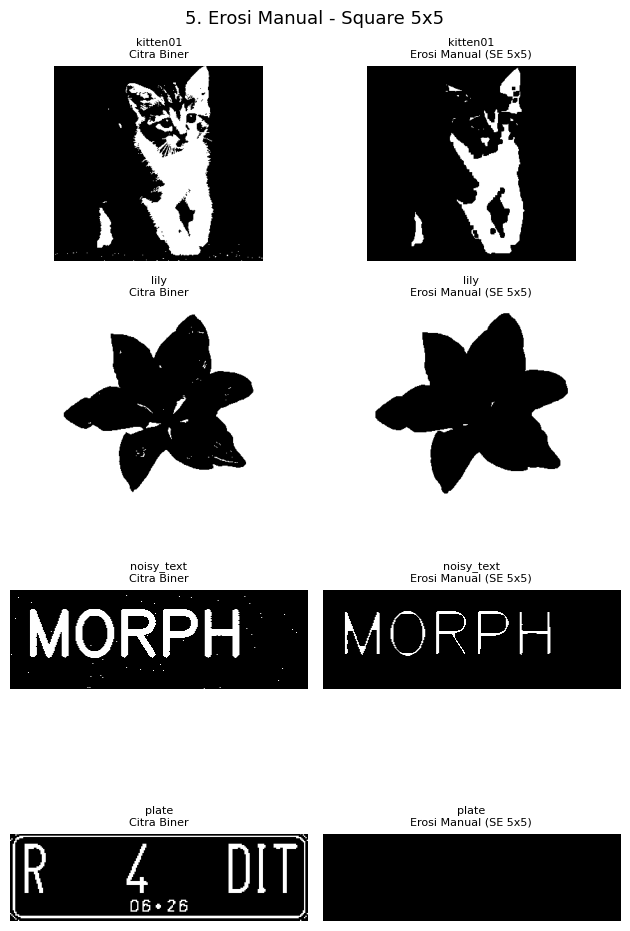

In [9]:
# 9. Erosi manual SE square 5x5
SE = se_square(5)
hasil = {n: [BINER[n], erosi_manual(BINER[n], SE)] for n in BINER}
tampil_step(['Citra Biner', 'Erosi Manual (SE 5x5)'], hasil,
            '5. Erosi Manual - Square 5x5')


### 6. Erosi dengan library OpenCV - SE square 5x5

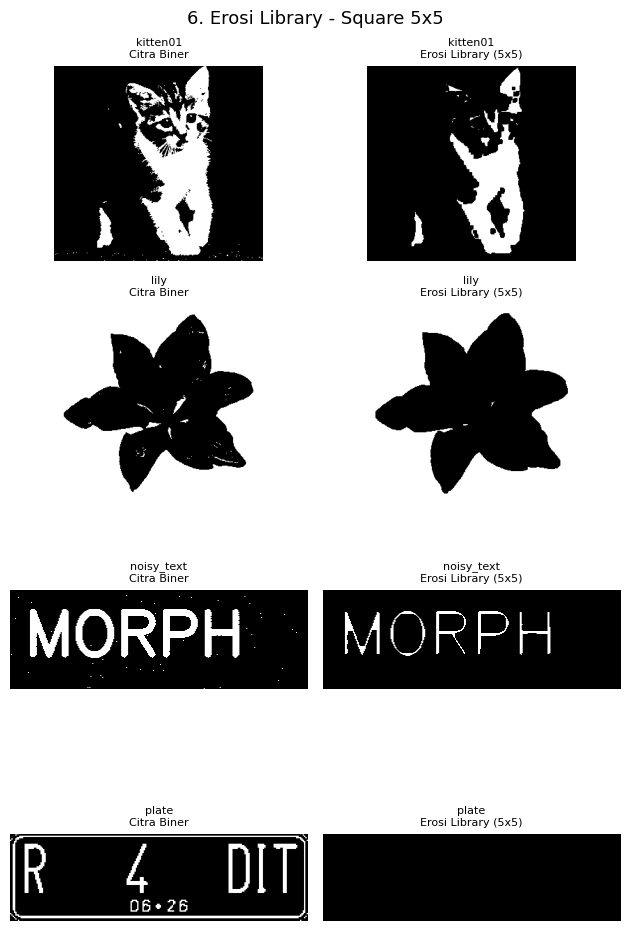

In [10]:
# 10. Erosi library cv2.erode SE square 5x5
SE = se_square(5)
hasil = {n: [BINER[n], cv2.erode(BINER[n], SE, iterations=1)] for n in BINER}
tampil_step(['Citra Biner', 'Erosi Library (5x5)'], hasil,
            '6. Erosi Library - Square 5x5')


### 7. Opening (erosi lalu dilasi) - SE square 3x3, manual vs library

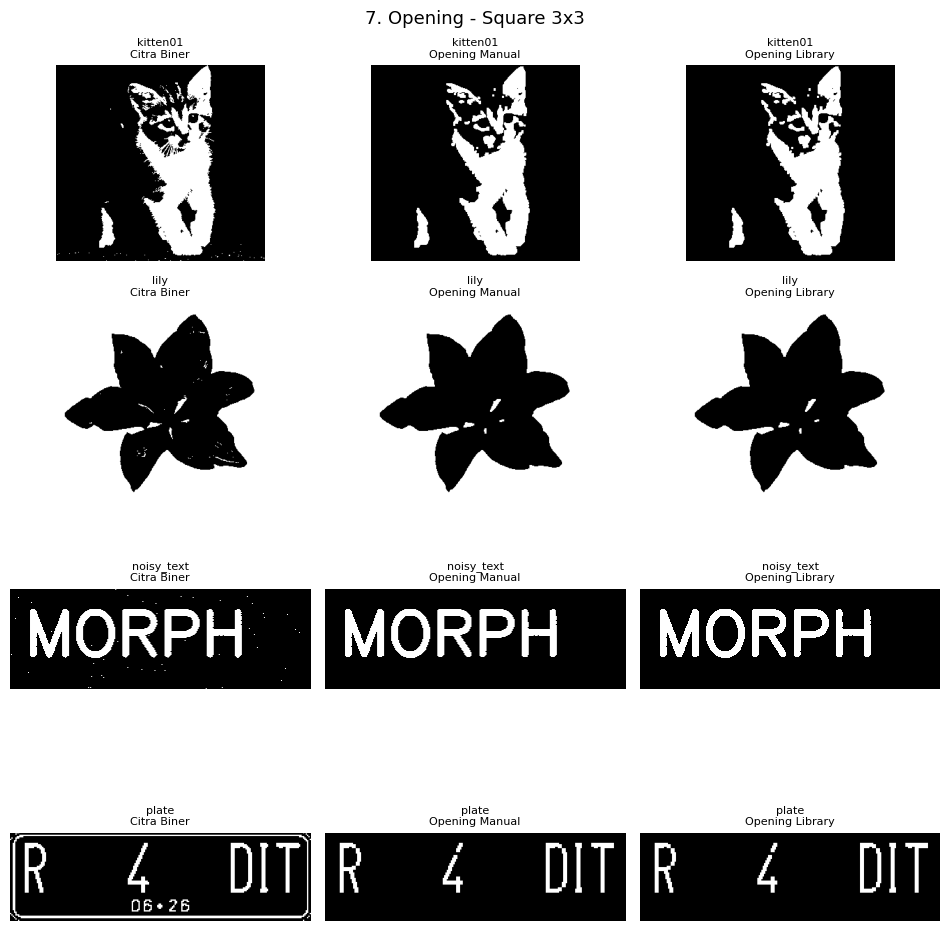

Hasil manual identik dengan library: True


In [11]:
# 11. Opening manual (erosi -> dilasi) vs cv2.morphologyEx MORPH_OPEN
SE = se_square(3)
manual_lib, sama = {}, True
for n in BINER:
    man = dilasi_manual(erosi_manual(BINER[n], SE), SE)
    lib = cv2.morphologyEx(BINER[n], cv2.MORPH_OPEN, SE)
    sama &= np.array_equal(man, lib)
    manual_lib[n] = [BINER[n], man, lib]

tampil_step(['Citra Biner', 'Opening Manual', 'Opening Library'], manual_lib,
            '7. Opening - Square 3x3')
print('Hasil manual identik dengan library:', sama)


### 8. Closing (dilasi lalu erosi) - SE square 3x3, manual vs library

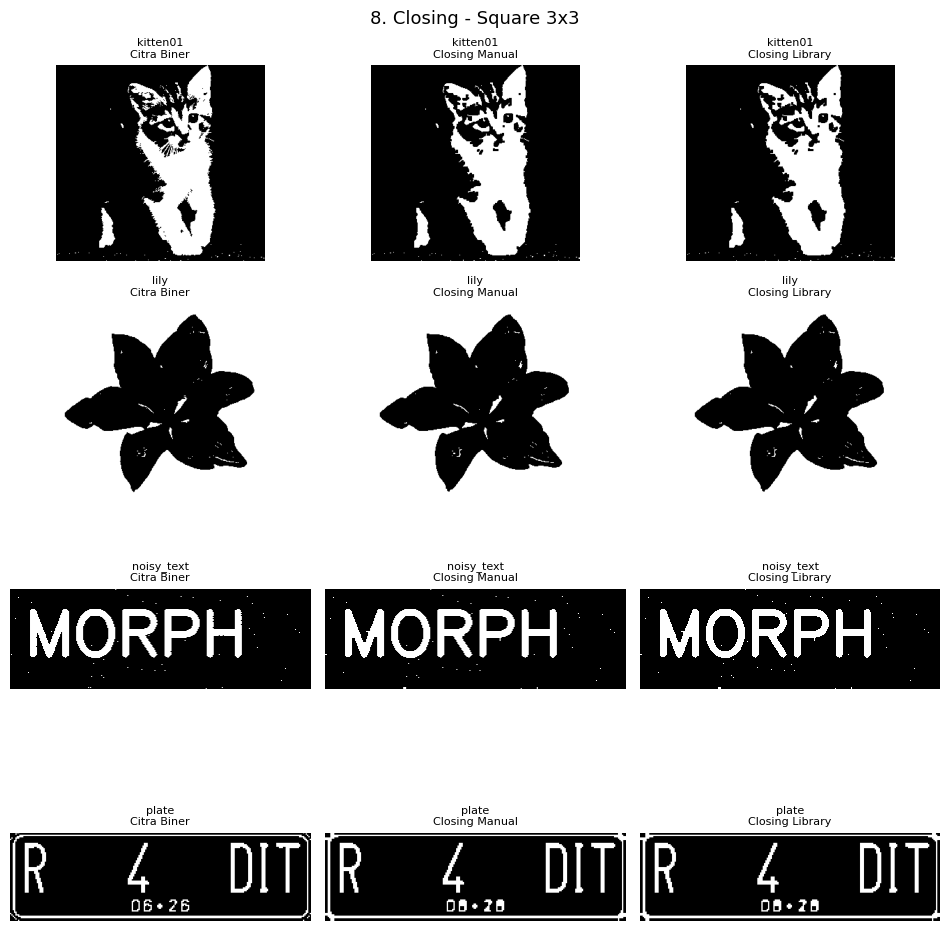

Hasil manual identik dengan library: True


In [12]:
# 12. Closing manual (dilasi -> erosi) vs cv2.morphologyEx MORPH_CLOSE
SE = se_square(3)
manual_lib, sama = {}, True
for n in BINER:
    man = erosi_manual(dilasi_manual(BINER[n], SE), SE)
    lib = cv2.morphologyEx(BINER[n], cv2.MORPH_CLOSE, SE)
    sama &= np.array_equal(man, lib)
    manual_lib[n] = [BINER[n], man, lib]

tampil_step(['Citra Biner', 'Closing Manual', 'Closing Library'], manual_lib,
            '8. Closing - Square 3x3')
print('Hasil manual identik dengan library:', sama)


### 9. Dilasi - SE cross 3x3 dan 5x5

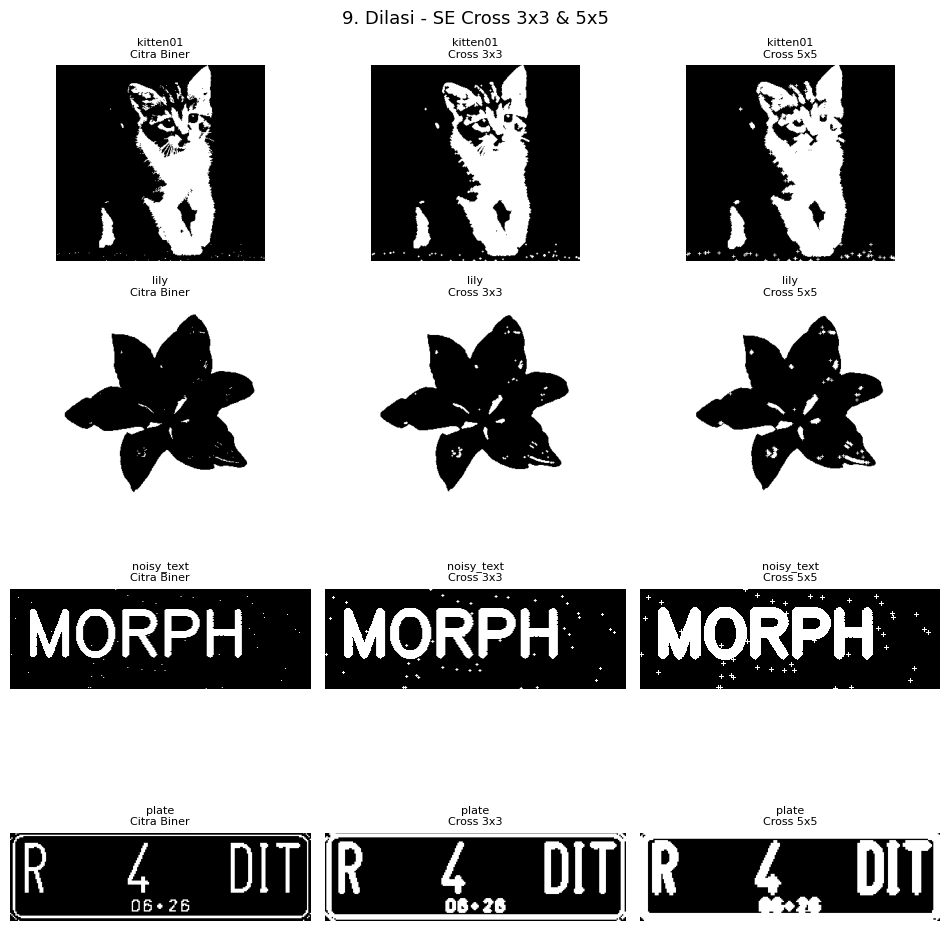

In [13]:
# 13. Dilasi manual SE cross 3x3 dan 5x5
se3, se5 = se_cross(3), se_cross(5)
hasil = {n: [BINER[n], dilasi_manual(BINER[n], se3), dilasi_manual(BINER[n], se5)]
         for n in BINER}
tampil_step(['Citra Biner', 'Cross 3x3', 'Cross 5x5'], hasil,
            '9. Dilasi - SE Cross 3x3 & 5x5')


### 10. Dilasi - SE circular (ellipse) 3x3 dan 5x5

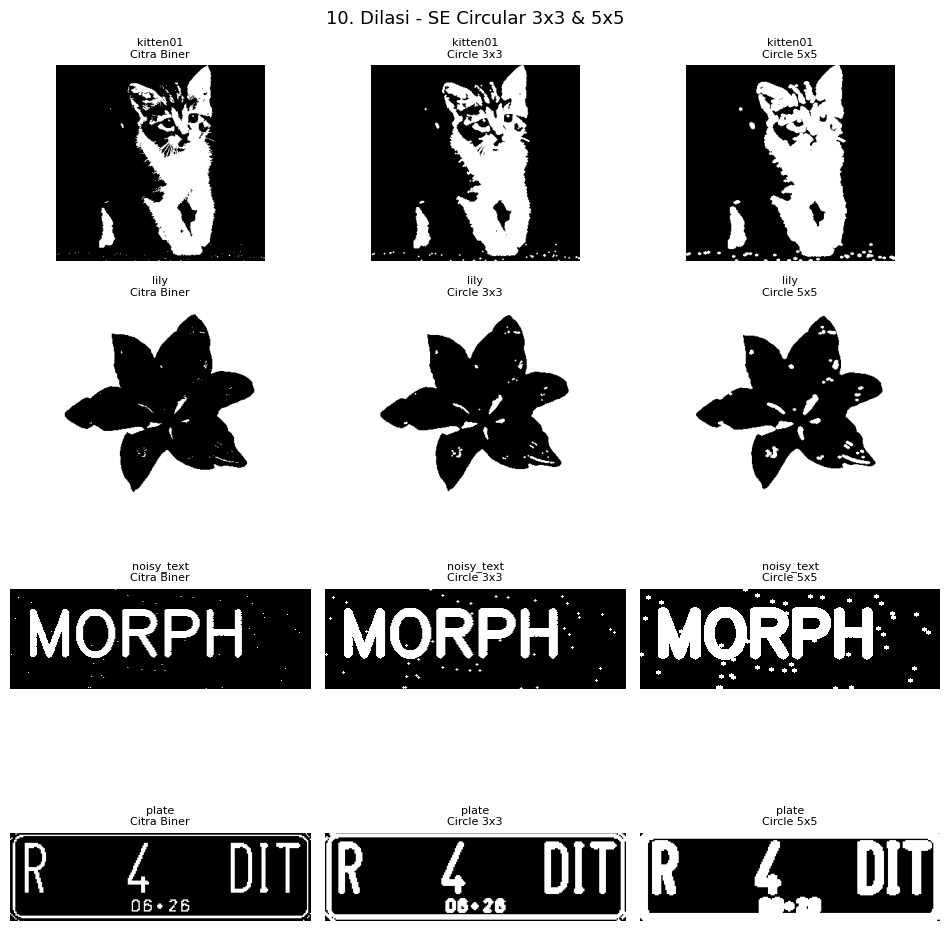

In [14]:
# 14. Dilasi manual SE circular 3x3 dan 5x5
se3, se5 = se_circle(3), se_circle(5)
hasil = {n: [BINER[n], dilasi_manual(BINER[n], se3), dilasi_manual(BINER[n], se5)]
         for n in BINER}
tampil_step(['Citra Biner', 'Circle 3x3', 'Circle 5x5'], hasil,
            '10. Dilasi - SE Circular 3x3 & 5x5')


### 11. Erosi - SE rectangle 3x5 dan 5x7

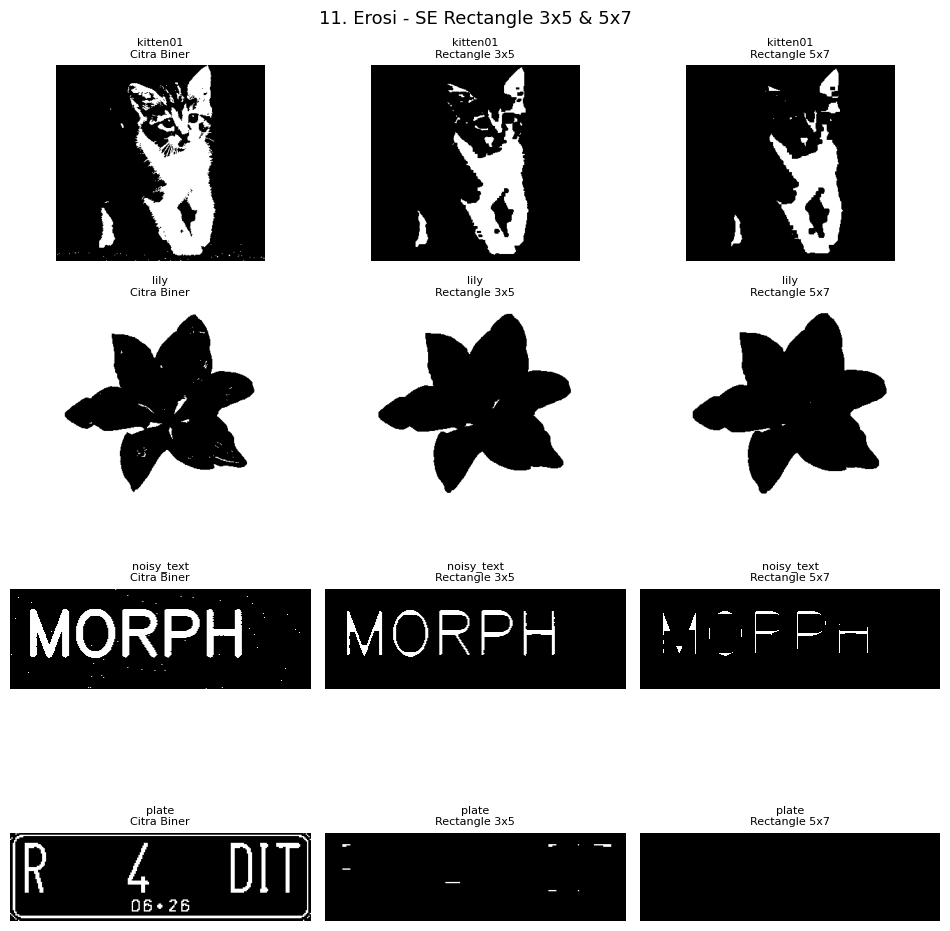

In [15]:
# 15. Erosi manual SE rectangle 3x5 dan 5x7
se35, se57 = se_rect(3, 5), se_rect(5, 7)
hasil = {n: [BINER[n], erosi_manual(BINER[n], se35), erosi_manual(BINER[n], se57)]
         for n in BINER}
tampil_step(['Citra Biner', 'Rectangle 3x5', 'Rectangle 5x7'], hasil,
            '11. Erosi - SE Rectangle 3x5 & 5x7')


### 12. Erosi - SE line vertikal 3 dan 5

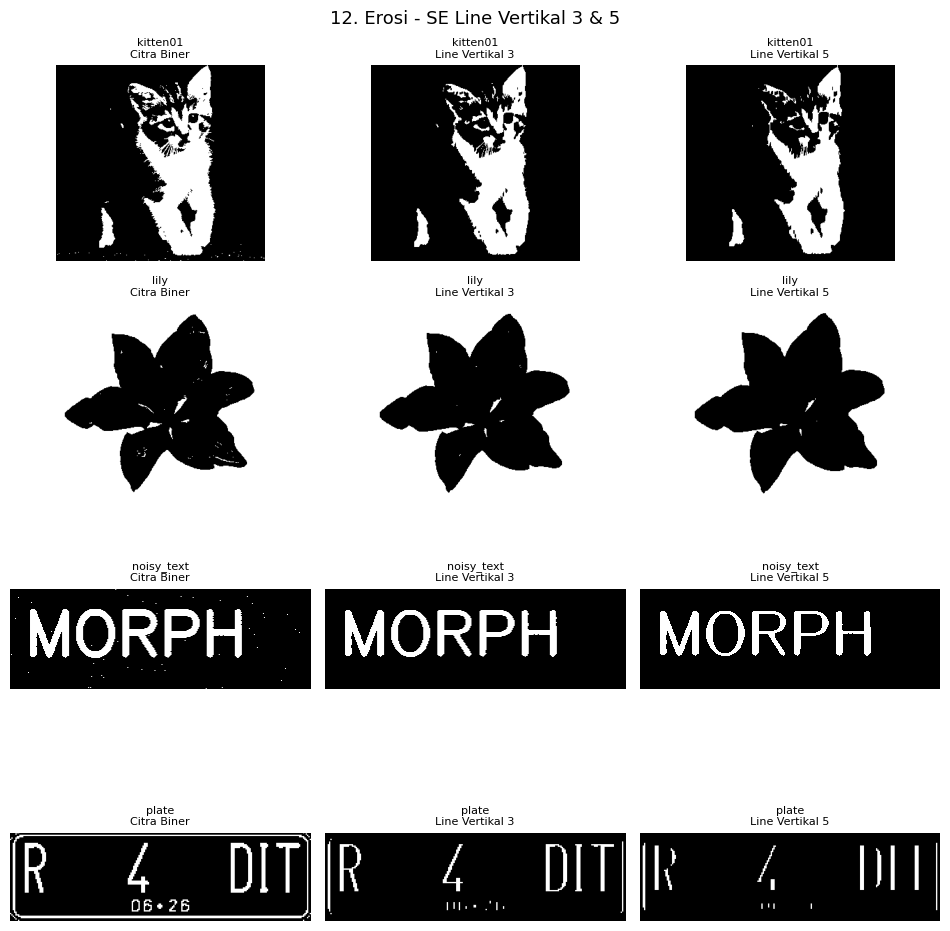

In [16]:
# 16. Erosi manual SE line vertikal 3 dan 5
se3, se5 = se_line_vertikal(3), se_line_vertikal(5)
hasil = {n: [BINER[n], erosi_manual(BINER[n], se3), erosi_manual(BINER[n], se5)]
         for n in BINER}
tampil_step(['Citra Biner', 'Line Vertikal 3', 'Line Vertikal 5'], hasil,
            '12. Erosi - SE Line Vertikal 3 & 5')


### 13. Transformasi Top-hat - SE 3x3

`Top-hat = citra - opening(citra)`, sehingga yang tersisa adalah detail kecil/terang.

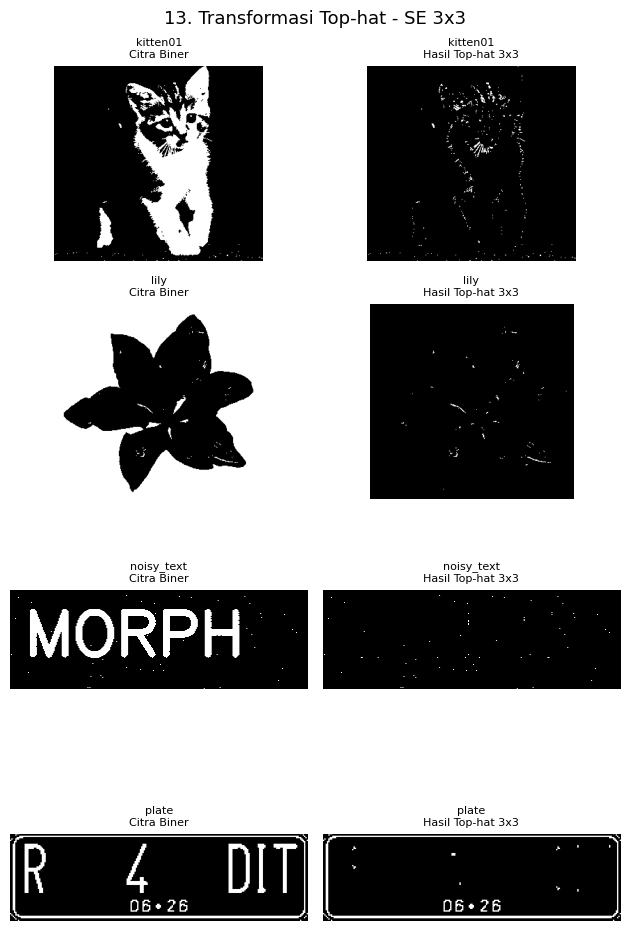

In [17]:
# 17. Top-hat biner SE rect 3x3
SE = se_rect(3, 3)
hasil = {n: [BINER[n], cv2.morphologyEx(BINER[n], cv2.MORPH_TOPHAT, SE)]
         for n in BINER}
tampil_step(['Citra Biner', 'Hasil Top-hat 3x3'], hasil,
            '13. Transformasi Top-hat - SE 3x3')


### 14. Transformasi Black-hat - SE 3x3

`Black-hat = closing(citra) - citra`.

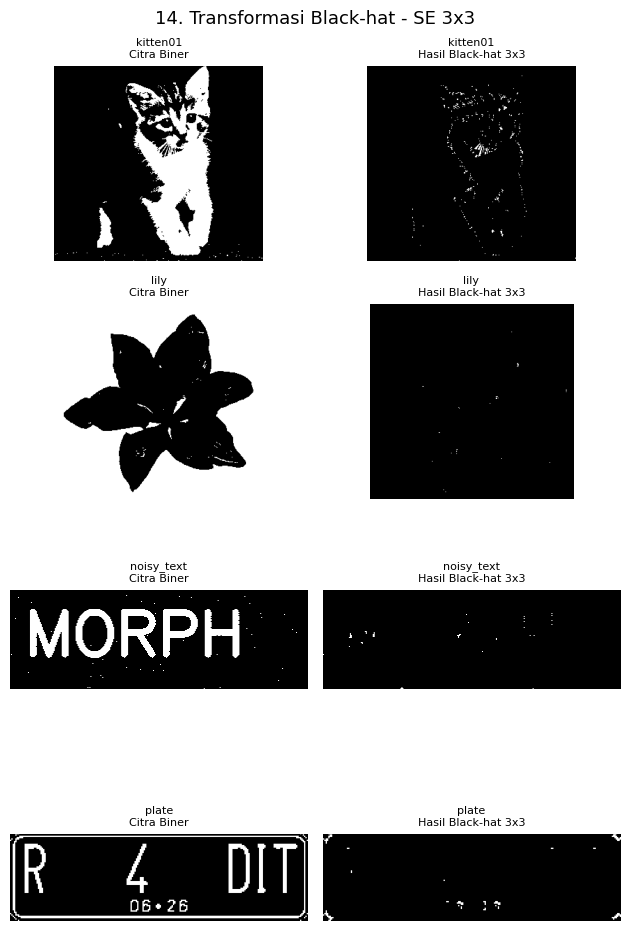

In [18]:
# 18. Black-hat biner SE rect 3x3
SE = se_rect(3, 3)
hasil = {n: [BINER[n], cv2.morphologyEx(BINER[n], cv2.MORPH_BLACKHAT, SE)]
         for n in BINER}
tampil_step(['Citra Biner', 'Hasil Black-hat 3x3'], hasil,
            '14. Transformasi Black-hat - SE 3x3')


### 15. Skeleton pada citra biner

kitten01     piksel rangka = 2442
lily         piksel rangka = 1477
noisy_text   piksel rangka = 614
plate        piksel rangka = 944


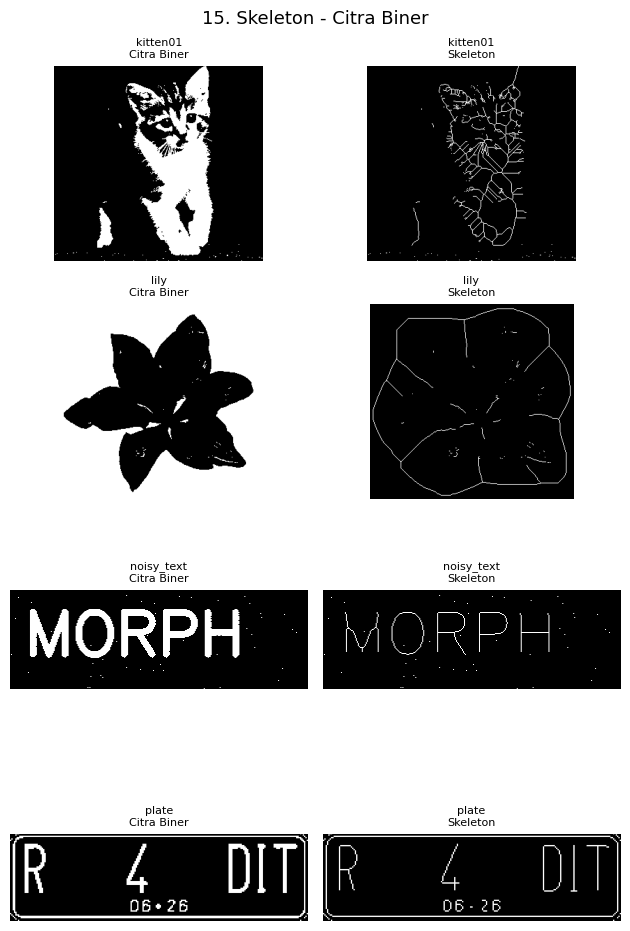

In [19]:
# 19. Skeletonize citra biner
hasil = {}
for n in BINER:
    skel = skeletonize(BINER[n] > 0).astype(np.uint8) * 255
    hasil[n] = [BINER[n], skel]
    print(f'{n:12s} piksel rangka = {int((skel > 0).sum())}')

tampil_step(['Citra Biner', 'Skeleton'], hasil,
            '15. Skeleton - Citra Biner')


### 16. Skeleton pada citra hasil inversi

Pada inversi, objek yang dirangkai adalah bagian **gelap** citra biner.

kitten01     piksel rangka invers = 4053
lily         piksel rangka invers = 2030
noisy_text   piksel rangka invers = 1514
plate        piksel rangka invers = 1472


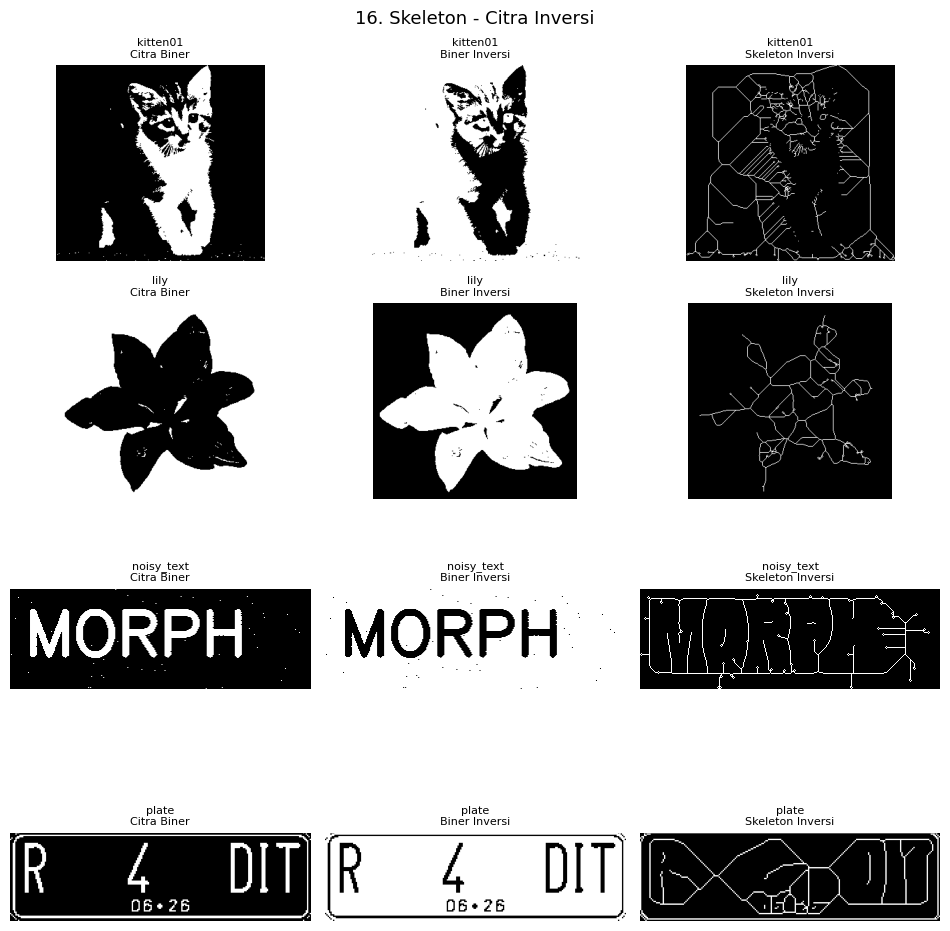

In [20]:
# 20. Skeletonize citra biner terinversi
hasil = {}
for n in BINER:
    inv = cv2.bitwise_not(BINER[n])
    skel = skeletonize(inv > 0).astype(np.uint8) * 255
    hasil[n] = [BINER[n], inv, skel]
    print(f'{n:12s} piksel rangka invers = {int((skel > 0).sum())}')

tampil_step(['Citra Biner', 'Biner Inversi', 'Skeleton Inversi'], hasil,
            '16. Skeleton - Citra Inversi')


### 17. Thinning (`morphology.thin`) vs skeletonize

kitten01     piksel skeleton=2442  thin=2686  beda=2508
lily         piksel skeleton=1477  thin=1410  beda=2193
noisy_text   piksel skeleton= 614  thin= 614  beda=284
plate        piksel skeleton= 944  thin= 933  beda=515


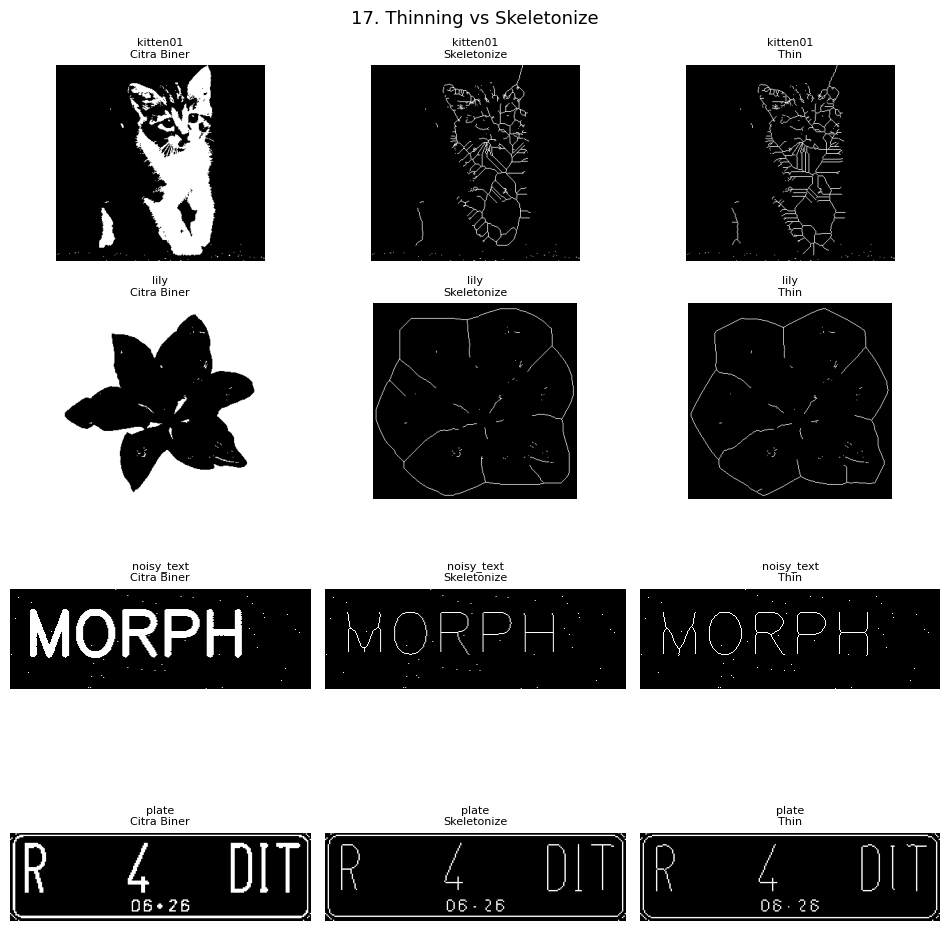

In [21]:
# 21. Thinning dibandingkan dengan skeletonize
hasil = {}
for n in BINER:
    b = BINER[n] > 0
    skel = skeletonize(b).astype(np.uint8) * 255
    tipis = thin(b).astype(np.uint8) * 255
    beda = int((skel != tipis).sum())
    hasil[n] = [BINER[n], skel, tipis]
    print(f'{n:12s} piksel skeleton={int((skel>0).sum()):4d}  '
          f'thin={int((tipis>0).sum()):4d}  beda={beda}')

tampil_step(['Citra Biner', 'Skeletonize', 'Thin'], hasil,
            '17. Thinning vs Skeletonize')


---

## Kesimpulan singkat

1. **Dilasi** menebalkan objek putih dan menutup lubang kecil; besar `SE` menentukan besar penebalan.
2. **Erosi** menipiskan objek dan menghilangkan detail kecil; SE `line vertikal` hanya menyisakan bagian yang vertikal.
3. **Opening** menghapus noise/objek kecil tanpa banyak mengubah ukuran objek utama; **Closing** mengisi lubang dan celah kecil.
4. **Top-hat** menyisakan detail terang yang lebih kecil dari SE; **Black-hat** menyisakan lubang/celah yang lebih kecil dari SE.
5. **Skeletonize** dan **thin** sama-sama menyusutkan objek menjadi rangka 1 piksel; hasil keduanya identik secara visual, dengan `thin` menjaga lebih banyak cabang pada sebagian citra.
6. Implementasi **manual** (loop `max`/`min`) menghasilkan citra yang sama dengan fungsi library OpenCV.
